# 03 CatBoost Discrete-Time Survival

## 1. Импорты и пути

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from catboost import CatBoostClassifier, Pool
from sklearn.metrics import roc_auc_score, average_precision_score, log_loss, brier_score_loss

ROOT = Path(r"C:\Users\Ева\Desktop\Хакатон Альфа\AURELIUS\scoring")
DATA_PATH = ROOT / "data" / "processed" / "ml_survival_dataset.parquet"
BASELINE_DIR = ROOT / "models" / "experiments" / "survival_v3_baseline"
EXP_DIR = ROOT / "models" / "experiments" / "survival_v3_discrete_time"
EXP_DIR.mkdir(parents=True, exist_ok=True)
SEED = 42

for path in [DATA_PATH, BASELINE_DIR / "splits.npz", BASELINE_DIR / "features.json"]:
    if not path.exists():
        raise FileNotFoundError(path)
print("Каталог эксперимента:", EXP_DIR)

Каталог эксперимента: C:\Users\Ева\Desktop\Хакатон Альфа\AURELIUS\scoring\models\experiments\survival_v3_discrete_time


## 2. Загрузка эпизодов и фиксированного разбиения

In [2]:
df = pd.read_parquet(DATA_PATH)
with np.load(BASELINE_DIR / "splits.npz") as s:
    train_idx, val_idx, test_idx = (s[k].copy() for k in ["train_idx", "val_idx", "test_idx"])
with open(BASELINE_DIR / "features.json", encoding="utf-8") as f:
    feature_config = json.load(f)
BASE_FEATURES = feature_config["features"]
CAT_FEATURES = feature_config["categorical_features"]
FEATURES = [f for f in BASE_FEATURES if f != "term_months"]
MODEL_FEATURES = FEATURES + ["month_on_book"]

assert len(df) == 200_000, f"Неожиданный размер: {len(df)}"
assert len(np.unique(np.concatenate([train_idx, val_idx, test_idx]))) == len(df)
assert set(df.iloc[train_idx].borrower_id).isdisjoint(df.iloc[val_idx].borrower_id)
assert set(df.iloc[train_idx].borrower_id).isdisjoint(df.iloc[test_idx].borrower_id)
assert set(df.iloc[val_idx].borrower_id).isdisjoint(df.iloc[test_idx].borrower_id)

df_train = df.iloc[train_idx].copy()
df_val = df.iloc[val_idx].copy()
print("Эпизоды train / val / test (test отложен):", len(df_train), len(df_val), len(test_idx))
print("Признаки модели:", MODEL_FEATURES)

Эпизоды train / val / test (test отложен): 140000 30000 30000
Признаки модели: ['age_months', 'industry', 'entity_type', 'monthly_revenue', 'revenue_trend_12m', 'revenue_volatility', 'operating_margin', 'cash_buffer_months', 'dscr', 'debt_to_revenue', 'prior_overdue_30d', 'requested_amount', 'annual_rate', 'macro_stress', 'month_on_book']


## 3. Преобразование эпизодов в кредито-месяцы

In [3]:
def make_person_month_dataset(episodes, features):
    src = episodes.reset_index(drop=True)
    durations = src["duration"].to_numpy(dtype=np.int32)
    events = src["event"].to_numpy(dtype=np.int8)
    terms = src["term_months"].to_numpy(dtype=np.int32)
    if np.any(durations < 1) or np.any(durations > terms):
        raise ValueError("Некорректная длительность наблюдения")
    indices = np.repeat(np.arange(len(src)), durations)
    ends = np.cumsum(durations, dtype=np.int64)
    starts = ends - durations
    months = (np.arange(len(indices), dtype=np.int64) - np.repeat(starts, durations) + 1).astype(np.int16)
    cols = list(dict.fromkeys(["borrower_id", "episode_id"] + features))
    out = src.iloc[indices][cols].reset_index(drop=True)
    out["month_on_book"] = months
    labels = np.zeros(len(indices), dtype=np.int8)
    labels[ends - 1] = events
    out["default_next"] = labels
    assert int(out.default_next.sum()) == int(events.sum())
    return out

train_monthly = make_person_month_dataset(df_train, FEATURES)
val_monthly = make_person_month_dataset(df_val, FEATURES)
print("Train кредито-месяцев:", len(train_monthly), "событий:", int(train_monthly.default_next.sum()))
print("Val кредито-месяцев:", len(val_monthly), "событий:", int(val_monthly.default_next.sum()))
print("Доля событий в месяц (train):", f"{train_monthly.default_next.mean():.3%}")
print("Доля событий в месяц (val):", f"{val_monthly.default_next.mean():.3%}")

Train кредито-месяцев: 2913959 событий: 40113
Val кредито-месяцев: 628153 событий: 8524
Доля событий в месяц (train): 1.377%
Доля событий в месяц (val): 1.357%


## 4. Обучение CatBoostClassifier

In [4]:
X_train = train_monthly[MODEL_FEATURES].copy()
X_val = val_monthly[MODEL_FEATURES].copy()
y_train = train_monthly["default_next"].to_numpy(dtype=np.int8)
y_val = val_monthly["default_next"].to_numpy(dtype=np.int8)
for col in CAT_FEATURES:
    X_train[col] = X_train[col].fillna("UNKNOWN").astype(str)
    X_val[col] = X_val[col].fillna("UNKNOWN").astype(str)

train_pool = Pool(X_train, label=y_train, cat_features=CAT_FEATURES)
val_pool = Pool(X_val, label=y_val, cat_features=CAT_FEATURES)

model = CatBoostClassifier(
    iterations=1000,
    depth=6,
    learning_rate=0.03,
    l2_leaf_reg=3,
    loss_function="Logloss",
    eval_metric="Logloss",
    random_seed=SEED,
    early_stopping_rounds=100,
    verbose=100,
    thread_count=-1,
    allow_writing_files=False,
)
model.fit(train_pool, eval_set=val_pool, use_best_model=True)
print("Лучшая итерация:", model.best_iteration_)
print("Лучшие значения:", model.best_score_)

0:	learn: 0.6328581	test: 0.6328295	best: 0.6328295 (0)	total: 890ms	remaining: 14m 49s
100:	learn: 0.0704846	test: 0.0697490	best: 0.0697490 (100)	total: 1m 6s	remaining: 9m 48s
200:	learn: 0.0698335	test: 0.0691068	best: 0.0691068 (200)	total: 2m 9s	remaining: 8m 34s
300:	learn: 0.0696688	test: 0.0689928	best: 0.0689928 (300)	total: 3m 13s	remaining: 7m 28s
400:	learn: 0.0695619	test: 0.0689409	best: 0.0689409 (400)	total: 4m 16s	remaining: 6m 22s
500:	learn: 0.0694632	test: 0.0688917	best: 0.0688913 (498)	total: 5m 19s	remaining: 5m 18s
600:	learn: 0.0693721	test: 0.0688649	best: 0.0688648 (598)	total: 6m 23s	remaining: 4m 14s
700:	learn: 0.0692937	test: 0.0688452	best: 0.0688452 (700)	total: 7m 27s	remaining: 3m 10s
800:	learn: 0.0692261	test: 0.0688394	best: 0.0688393 (799)	total: 8m 29s	remaining: 2m 6s
900:	learn: 0.0691570	test: 0.0688360	best: 0.0688352 (835)	total: 9m 31s	remaining: 1m 2s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.06883518761
bestIte

## 5. Метрики условного месячного риска на validation

In [5]:
val_hazard = model.predict_proba(X_val)[:, 1]
monthly_metrics = {
    "roc_auc": float(roc_auc_score(y_val, val_hazard)),
    "pr_auc": float(average_precision_score(y_val, val_hazard)),
    "logloss": float(log_loss(y_val, val_hazard)),
    "brier": float(brier_score_loss(y_val, val_hazard)),
    "event_rate": float(np.mean(y_val)),
    "mean_predicted_hazard": float(np.mean(val_hazard)),
}
print(pd.Series(monthly_metrics).to_string(float_format=lambda x: f"{x:.6f}"))
print("\nПримечание: это метрики условного месячного риска, не накопленной PD_T.")

roc_auc                 0.666438
pr_auc                  0.036136
logloss                 0.068835
brier                   0.013261
event_rate              0.013570
mean_predicted_hazard   0.013833

Примечание: это метрики условного месячного риска, не накопленной PD_T.


## 6. Прогноз помесячной PD по заявке

In [6]:
def predict_pd_curves(model, applications, features, cat_features, batch_size=2500):
    apps = applications.reset_index(drop=True)
    hazards_all, pd_all = [], []
    for left in range(0, len(apps), batch_size):
        chunk = apps.iloc[left:left + batch_size]
        terms = chunk["term_months"].to_numpy(dtype=np.int32)
        if np.any(terms < 1):
            raise ValueError("term_months должен быть положительным")
        ids = np.repeat(np.arange(len(chunk)), terms)
        ends = np.cumsum(terms, dtype=np.int64)
        starts = ends - terms
        months = (np.arange(len(ids)) - np.repeat(starts, terms) + 1).astype(np.int16)
        future = chunk.iloc[ids][features].reset_index(drop=True)
        future["month_on_book"] = months
        for col in cat_features:
            future[col] = future[col].fillna("UNKNOWN").astype(str)
        h_flat = model.predict_proba(future[features + ["month_on_book"]])[:, 1]
        begin = 0
        for t in terms:
            h = np.clip(h_flat[begin:begin + t], 0, 1)
            cumulative_pd = -np.expm1(np.cumsum(np.log1p(-h)))
            hazards_all.append(h)
            pd_all.append(cumulative_pd)
            begin += t
    return hazards_all, pd_all

val_36 = df_val.loc[df_val.term_months == 36].copy().reset_index(drop=True)
hazards_36, curves_36 = predict_pd_curves(model, val_36, FEATURES, CAT_FEATURES)
pd36 = np.array([curve[-1] for curve in curves_36])
print("Количество кредитов на 36 мес.:", len(val_36))
print("PD36: min / median / max =", *(f"{x:.2%}" for x in [pd36.min(), np.median(pd36), pd36.max()]))

Количество кредитов на 36 мес.: 7185
PD36: min / median / max = 18.06% 34.07% 100.00%


## 7. График кривых PD36

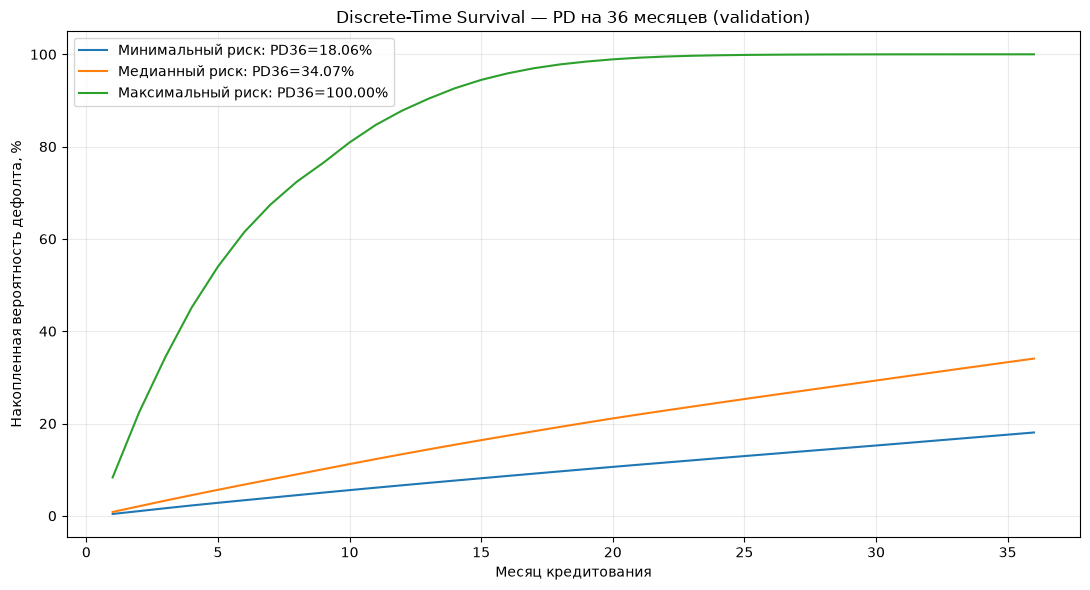

In [7]:
order = np.argsort(pd36)
selected = [order[0], order[len(order)//2], order[-1]]
labels = ["Минимальный риск", "Медианный риск", "Максимальный риск"]
plt.figure(figsize=(11, 6))
for i, label in zip(selected, labels):
    plt.plot(np.arange(1, 37), 100 * curves_36[i], label=f"{label}: PD36={pd36[i]:.2%}")
plt.xlabel("Месяц кредитования")
plt.ylabel("Накопленная вероятность дефолта, %")
plt.title("Discrete-Time Survival — PD на 36 месяцев (validation)")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.savefig(EXP_DIR / "pd_curves_36m.png", dpi=160)
plt.show()

## 8. Дополнительная проверка накопленной PD: IPCW Brier и калибровка

In [9]:
from sksurv.util import Surv
from sksurv.metrics import brier_score
from sksurv.nonparametric import kaplan_meier_estimator

train_36 = df_train.loc[df_train.term_months == 36]

y_train_36 = Surv.from_arrays(
    event=train_36.event.to_numpy(dtype=bool),
    time=train_36.duration.to_numpy(dtype=float),
)

y_val_36 = Surv.from_arrays(
    event=val_36.event.to_numpy(dtype=bool),
    time=val_36.duration.to_numpy(dtype=float),
)

times = np.array([12.0, 24.0])

# Каждая строка — один кредитный эпизод
# Столбцы — вероятность выживания к 12 и 24 месяцам
surv_probs = np.array([
    1.0 - np.asarray(curve)[[11, 23]]
    for curve in curves_36
], dtype=float)

print("Количество эпизодов:", len(val_36))
print("Форма матрицы:", surv_probs.shape)

assert surv_probs.shape == (len(val_36), len(times))
assert np.isfinite(surv_probs).all()

_, bs = brier_score(
    y_train_36,
    y_val_36,
    surv_probs,
    times,
)

brier_df = pd.DataFrame({
    "month": times.astype(int),
    "ipcw_brier": bs,
})

print(brier_df.to_string(index=False))

Количество эпизодов: 7185
Форма матрицы: (7185, 2)
 month  ipcw_brier
    12    0.124458
    24    0.183440


## 9. Сохранение модели и артефактов

In [11]:
model.save_model(str(EXP_DIR / "model.cbm"))
config = {
    "experiment": "survival_v3_discrete_time",
    "model_type": "CatBoostClassifier",
    "approach": "Discrete-Time Survival",
    "prediction_time": "loan_origination",
    "future_realized_covariates": False,
    "target": "conditional_monthly_default_hazard",
    "features": MODEL_FEATURES,
    "categorical_features": CAT_FEATURES,
    "excluded_feature": "term_months (used only as prediction horizon)",
    "model_params": model.get_params(),
    "seed": SEED,
    "dataset": str(DATA_PATH),
    "split_source": str(BASELINE_DIR / "splits.npz"),
}
metrics = {
    "best_iteration": int(model.best_iteration_),
    "best_score": model.best_score_,
    "train_episodes": len(df_train),
    "validation_episodes": len(df_val),
    "train_monthly_rows": len(train_monthly),
    "validation_monthly_rows": len(val_monthly),
    "monthly_metrics": monthly_metrics,
    "validation_36m": {
        "n": len(val_36),
        "ipcw_brier_12m": float(bs[0]),
        "ipcw_brier_24m": float(bs[1]),
        "pd36_min": float(pd36.min()),
        "pd36_median": float(np.median(pd36)),
        "pd36_max": float(pd36.max()),
    },
}
for filename, payload in [("config.json", config), ("metrics.json", metrics), ("features.json", {"features": MODEL_FEATURES, "categorical_features": CAT_FEATURES})]:
    with open(EXP_DIR / filename, "w", encoding="utf-8") as f:
        json.dump(payload, f, ensure_ascii=False, indent=2, default=str)

history = model.get_evals_result()
pd.DataFrame({f"{part}/{metric}": values for part, scores in history.items() for metric, values in scores.items()}).to_csv(
    EXP_DIR / "training_history.csv", index=False
)
validation_predictions = val_monthly[["borrower_id", "episode_id", "month_on_book", "default_next"]].copy()
validation_predictions["predicted_hazard"] = val_hazard
validation_predictions.to_parquet(EXP_DIR / "validation_predictions.parquet", index=False)

pd.DataFrame({
    "borrower_id": val_36.borrower_id.to_numpy(),
    "episode_id": val_36.episode_id.to_numpy(),
    "duration": val_36.duration.to_numpy(),
    "event": val_36.event.to_numpy(),
    "pd12": [c[11] for c in curves_36],
    "pd24": [c[23] for c in curves_36],
    "pd36": pd36,
}).to_parquet(EXP_DIR / "validation_pd_36m.parquet", index=False)

print("Сохранено в:", EXP_DIR)
for path in sorted(EXP_DIR.iterdir()):
    print(" -", path.name)

Сохранено в: C:\Users\Ева\Desktop\Хакатон Альфа\AURELIUS\scoring\models\experiments\survival_v3_discrete_time
 - config.json
 - features.json
 - metrics.json
 - model.cbm
 - pd_curves_36m.png
 - training_history.csv
 - validation_pd_36m.parquet
 - validation_predictions.parquet


,decile,n,predicted_pd12,observed_pd12_km
0,0,719,0.072318,0.063587
1,1,718,0.085096,0.089070
2,2,719,0.093529,0.100370
3,3,718,0.101353,0.107135
4,4,719,0.110810,0.141310
5,5,718,0.122823,0.124731
6,6,718,0.139478,0.137193
7,7,719,0.166691,0.155795
8,8,718,0.227217,0.261706
9,9,719,0.440865,0.456117


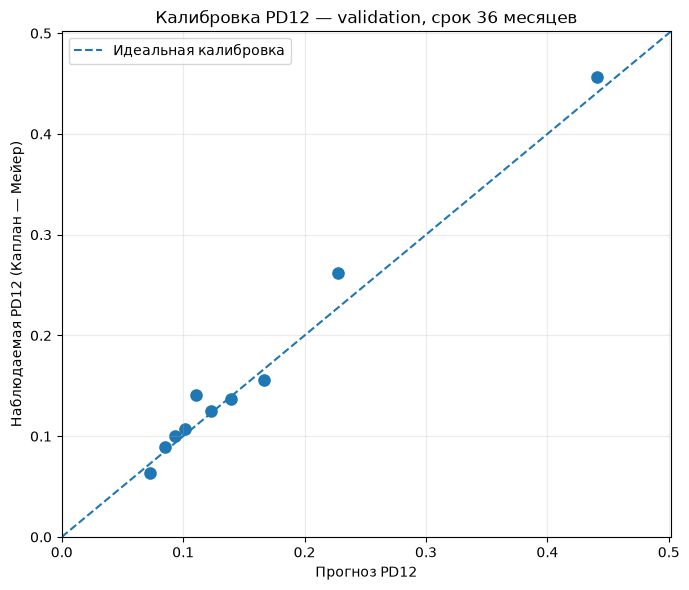


График сохранён: C:\Users\Ева\Desktop\Хакатон Альфа\AURELIUS\scoring\models\experiments\survival_v3_discrete_time\calibration_12m.png
Файл существует: True


In [12]:
from sksurv.nonparametric import kaplan_meier_estimator
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Данные для калибровки
cal = val_36[["duration", "event"]].copy().reset_index(drop=True)

cal["predicted_pd12"] = np.array([
    np.asarray(curve)[11]
    for curve in curves_36
])

cal["decile"] = pd.qcut(
    cal["predicted_pd12"],
    q=10,
    labels=False,
    duplicates="drop"
)

cal_rows = []

for group, part in cal.groupby("decile"):
    km_t, km_s = kaplan_meier_estimator(
        part["event"].to_numpy(dtype=bool),
        part["duration"].to_numpy(dtype=float)
    )

    idx = np.searchsorted(km_t, 12, side="right") - 1
    observed_pd12 = 1 - km_s[idx] if idx >= 0 else 0.0

    cal_rows.append({
        "decile": int(group),
        "n": len(part),
        "predicted_pd12": part["predicted_pd12"].mean(),
        "observed_pd12_km": observed_pd12
    })

cal_df = pd.DataFrame(cal_rows)

display(cal_df)

# Сохраняем таблицу
EXP_DIR.mkdir(parents=True, exist_ok=True)
cal_df.to_csv(EXP_DIR / "calibration_12m.csv", index=False)

# Строим график
fig, ax = plt.subplots(figsize=(7, 6))

ax.plot(
    [0, 1], [0, 1],
    "--",
    label="Идеальная калибровка"
)

ax.scatter(
    cal_df["predicted_pd12"],
    cal_df["observed_pd12_km"],
    s=65
)

max_value = max(
    0.05,
    cal_df[["predicted_pd12", "observed_pd12_km"]].max().max() * 1.1
)

ax.set_xlim(0, max_value)
ax.set_ylim(0, max_value)

ax.set_xlabel("Прогноз PD12")
ax.set_ylabel("Наблюдаемая PD12 (Каплан — Мейер)")
ax.set_title("Калибровка PD12 — validation, срок 36 месяцев")
ax.grid(alpha=0.25)
ax.legend()

fig.tight_layout()

# Сохраняем ДО plt.show()
save_path = EXP_DIR / "calibration_12m.png"
fig.savefig(save_path, dpi=160, bbox_inches="tight")

plt.show()

print(f"\nГрафик сохранён: {save_path.resolve()}")
print(f"Файл существует: {save_path.is_file()}")